# Figures and Tables

This notebook generates the figures and tables used in the final report.

It uses the cleaned and processed datasets created in the previous notebooks and does not repeat the data-cleaning or modelling stages. The figures are saved in the `figures/` folder so that they can be included directly in the paper.


In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_path = Path("/files/swiss-bank-risk-project")

data_path = project_path / "data" / "processed" / "clean_weekly_data.csv"
figures_path = project_path / "figures"

figures_path.mkdir(exist_ok=True)

In [3]:
df = pd.read_csv(data_path, parse_dates=["date"])

df.head()

,date,ciss_index,chf-eur_exchange_rate_control,commercial_bank_bond_yield,government_bond_yield,commercial_bank_bond_spread,snb_policy_rate
0,2010-01-08,0.165886,1.48398,2.1872,1.8552,0.3320,0.375
1,2010-01-15,0.145988,1.47692,2.1640,1.8228,0.3412,0.375
2,2010-01-22,0.186101,1.47398,2.1208,1.7722,0.3486,0.375
3,2010-01-29,0.245768,1.47118,2.1194,1.7716,0.3478,0.375
4,2010-02-05,0.229882,1.47136,2.0718,1.7392,0.3326,0.375


In [4]:
plot_df = df[df["date"] >= "2015-01-01"].copy()

plot_df.head()

,date,ciss_index,chf-eur_exchange_rate_control,commercial_bank_bond_yield,government_bond_yield,commercial_bank_bond_spread,snb_policy_rate
260,2015-01-02,0.007444,1.20255,0.4535,0.2280,0.2255,-0.75
261,2015-01-09,0.025402,1.20122,0.3630,0.1078,0.2552,-0.75
262,2015-01-16,0.028616,1.12876,0.2646,0.0142,0.2504,-0.75
263,2015-01-23,0.062939,0.99926,0.0048,-0.3500,0.3548,-0.75
264,2015-01-30,0.117127,1.02532,0.1148,-0.2908,0.4056,-0.75


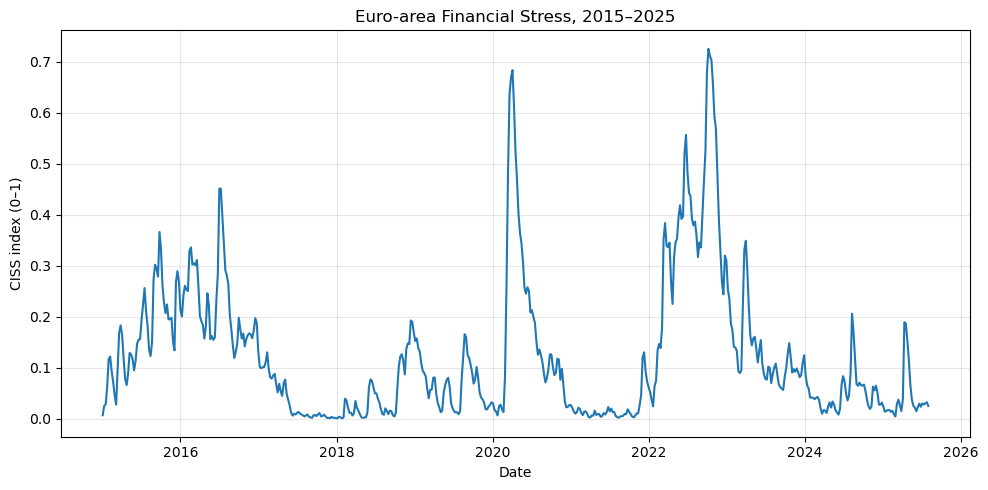

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(plot_df["date"], plot_df["ciss_index"])

ax.set_xlabel("Date")
ax.set_ylabel("CISS index (0–1)")
ax.set_title("Euro-area Financial Stress, 2015–2025")

ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(figures_path / "ciss_over_time.pdf", bbox_inches="tight")

plt.show()

**Figure 1.** Weekly euro-area CISS from 2015 to 2025. Higher values indicate higher financial stress.

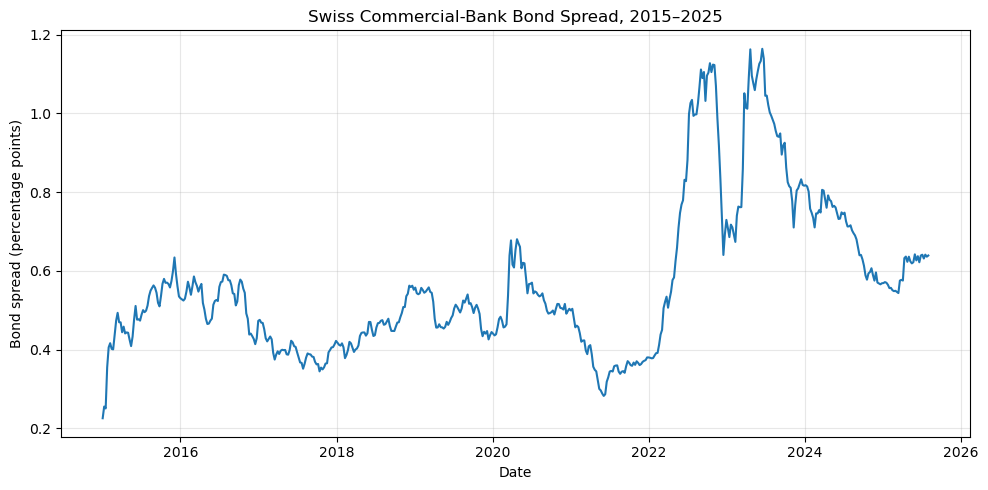

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(plot_df["date"], plot_df["commercial_bank_bond_spread"])

ax.set_xlabel("Date")
ax.set_ylabel("Bond spread (percentage points)")
ax.set_title("Swiss Commercial-Bank Bond Spread, 2015–2025")

ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(figures_path / "bank_bond_spread_over_time.pdf", bbox_inches="tight")

plt.show()

**Figure 2.** Weekly Swiss commercial-bank bond spread from 2015 to 2025. Higher values indicate a larger difference between commercial-bank and government bond yields.

In [7]:
model_performance = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3", "Decision Tree"],
    "Cross-validation ROC-AUC": [0.617, 0.593, 0.596, 0.661],
    "Out-of-sample ROC-AUC": [0.618, 0.519, 0.498, 0.436]
})

model_performance

,Model,Cross-validation ROC-AUC,Out-of-sample ROC-AUC
0,Model 1,0.617,0.618
1,Model 2,0.593,0.519
2,Model 3,0.596,0.498
3,Decision Tree,0.661,0.436


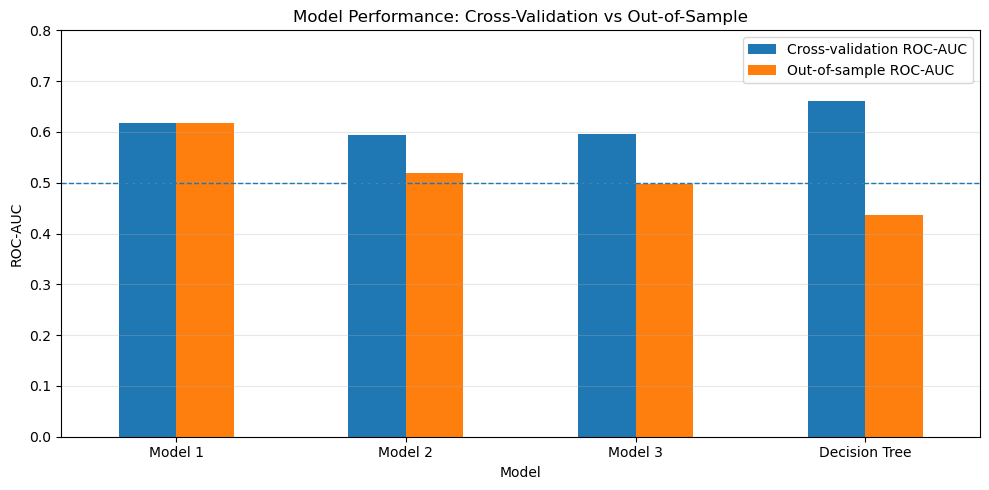

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))

model_performance.plot(
    x="Model",
    y=["Cross-validation ROC-AUC", "Out-of-sample ROC-AUC"],
    kind="bar",
    ax=ax
)

ax.axhline(0.5, linestyle="--", linewidth=1)

ax.set_xlabel("Model")
ax.set_ylabel("ROC-AUC")
ax.set_title("Model Performance: Cross-Validation vs Out-of-Sample")

ax.set_ylim(0, 0.8)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()

fig.savefig(figures_path / "roc_auc_comparison.pdf", bbox_inches="tight")

plt.show()

**Figure 3.** Cross-validation and out-of-sample ROC-AUC for each model. The decision tree performs best during cross-validation but performs poorly out of sample.

In [9]:
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

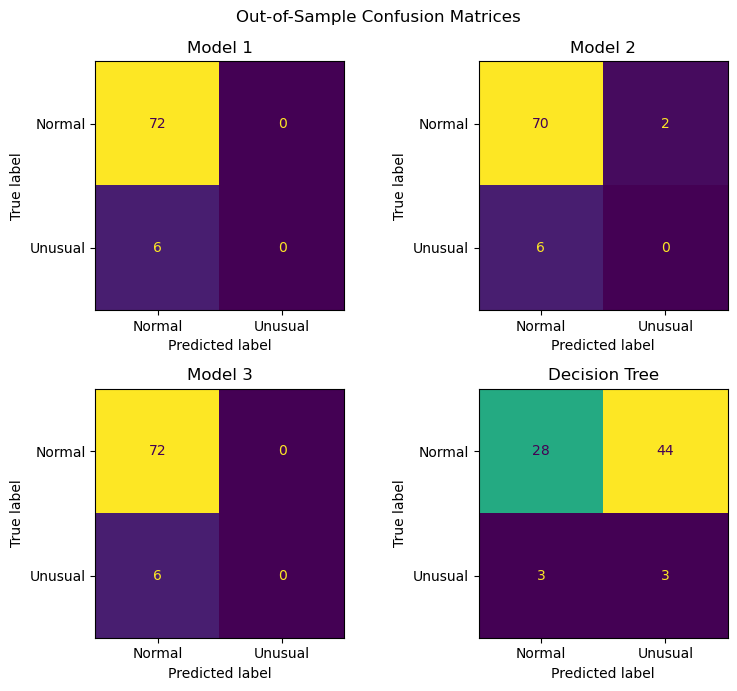

In [10]:
confusion_matrices = {
    "Model 1": np.array([[72, 0],
                         [6, 0]]),

    "Model 2": np.array([[70, 2],
                         [6, 0]]),

    "Model 3": np.array([[72, 0],
                         [6, 0]]),

    "Decision Tree": np.array([[28, 44],
                               [3, 3]])
}

# ChatGPT assistance: hints for plotting several confusion matrices in the same figure
# Start of AI-assisted block

fig, axes = plt.subplots(2, 2, figsize=(8, 7))

for ax, (model_name, matrix) in zip(axes.flatten(), confusion_matrices.items()):

    display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Normal", "Unusual"]
    )

    display.plot(ax=ax, colorbar=False)
    ax.set_title(model_name)

fig.suptitle("Out-of-Sample Confusion Matrices")

# End of AI-assisted block

fig.tight_layout()

fig.savefig(
    figures_path / "confusion_matrices.pdf",
    bbox_inches="tight"
)

plt.show()

**Figure 4.** Out-of-sample confusion matrices for each model. The logistic models do not identify any unusual spread-widening events, while the decision tree identifies three but also produces many false positives.

## Results table

This table contains the final out-of-sample performance of the four models used in the report.

In [11]:
results_table = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3", "Decision Tree"],
    "ROC-AUC": [0.618056, 0.518519, 0.497685, 0.436343],
    "Precision": [0.00000, 0.00000, 0.00000, 0.06383],
    "Recall": [0.0, 0.0, 0.0, 0.5],
    "F1 Score": [0.000000, 0.000000, 0.000000, 0.113208]
})

results_table

,Model,ROC-AUC,Precision,Recall,F1 Score
0,Model 1,0.618056,0.00000,0.0,0.000000
1,Model 2,0.518519,0.00000,0.0,0.000000
2,Model 3,0.497685,0.00000,0.0,0.000000
3,Decision Tree,0.436343,0.06383,0.5,0.113208


In [12]:
print("Figures created:")
for file in figures_path.iterdir():
    print(file.name)

Figures created:
bank_bond_spread_over_time.pdf
ciss_over_time.pdf
roc_auc_comparison.pdf
confusion_matrices.pdf
